# Physics-Guided RDBM MRI Reconstruction Results

This notebook summarizes the physics-guided RDBM experiments at 2×, 4×, 6×,
and 8× acceleration on the frozen 148-volume subset with supplied sensitivity
maps. The detailed checkpoint analysis uses the primary 4× experiment; the final
94,900-step checkpoints are also compared on the same held-out test split.

In [17]:
import html
import json
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mri-matplotlib")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, Markdown, display

working = Path.cwd()
PROJECT_ROOT = working if (working / "MRI_RECONSTRUCTION_PLAN.md").exists() else working.parent
EVALUATION_ROOT = Path(
    os.environ.get(
        "RDBM_EVALUATION_DIR",
        "/data/david_agyei/nyu-dataset/derived/rdbm_full_bf16/evaluation",
    )
)
MULTIRATE_ROOTS = {
    2: Path("/data/david_agyei/nyu-dataset/derived/rdbm_2x_bf16"),
    4: EVALUATION_ROOT.parent,
    6: Path("/data/david_agyei/nyu-dataset/derived/rdbm_6x_bf16"),
    8: Path("/data/david_agyei/nyu-dataset/derived/rdbm_8x_bf16"),
}
FIGURE_DIR = PROJECT_ROOT / "results" / "rdbm_evaluation"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

def read_json(path):
    return json.loads(Path(path).read_text())

def html_table(headers, rows):
    head = "".join(f"<th>{html.escape(str(value))}</th>" for value in headers)
    body = "".join(
        "<tr>" + "".join(f"<td>{html.escape(str(value))}</td>" for value in row) + "</tr>"
        for row in rows
    )
    return HTML(
        "<table style='border-collapse:collapse'>"
        f"<thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"
    )

## Load and verify the frozen evaluation

In [18]:
validation_paths = sorted((EVALUATION_ROOT / "val").glob("step-*/summary.json"))
validation = [read_json(path) for path in validation_paths]
selection = read_json(EVALUATION_ROOT / "best_validation_checkpoint.json")
test_path = EVALUATION_ROOT / "test" / f"step-{selection['checkpoint_step']:07d}" / "summary.json"
test = read_json(test_path)
no_dc_path = EVALUATION_ROOT / "test_no_dc" / f"step-{selection['checkpoint_step']:07d}" / "summary.json"
no_dc = read_json(no_dc_path) if no_dc_path.exists() else None

assert len(validation) >= 2
assert all(item["split"] == "val" and item["volume_count"] == 14 for item in validation)
assert test["split"] == "test" and test["volume_count"] == 14
assert test["checkpoint_step"] == selection["checkpoint_step"]
if no_dc is not None:
    assert no_dc["checkpoint_step"] == selection["checkpoint_step"]
    assert no_dc["apply_data_consistency"] is False

display(html_table(
    ["Split", "Volumes", "Slices", "Checkpoint"],
    [
        [
            "Validation",
            validation[0]["volume_count"],
            validation[0]["slice_count"],
            f"{validation[0]['checkpoint_step']:,}–{validation[-1]['checkpoint_step']:,} "
            f"({len(validation)} checkpoints)",
        ],
        ["Test", test["volume_count"], test["slice_count"], f"step {test['checkpoint_step']:,}"],
    ],
))

Split,Volumes,Slices,Checkpoint
Validation,14,220,"10,000–94,900 (10 checkpoints)"
Test,14,218,"step 94,900"


## Validation checkpoint selection

The evaluated checkpoints span the training trajectory through the final approximately
50-epoch checkpoint. PSNR is the selection metric; SSIM is the tie-breaker. All displayed averages first
aggregate slices within a volume and then weight the 14 volumes equally.

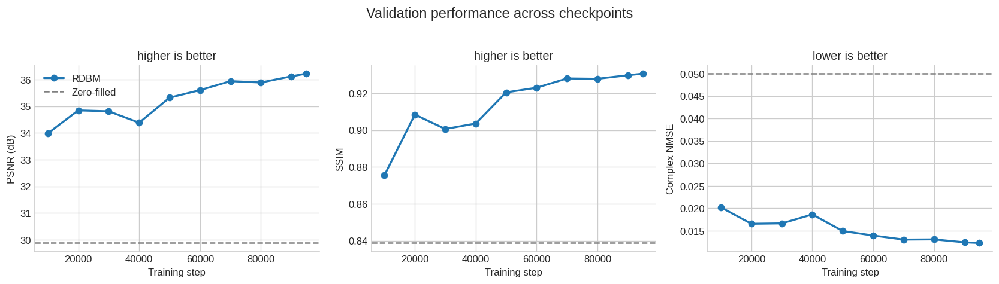

Step,PSNR,SSIM,Complex NMSE,Seconds/slice
"10,000",33.982,0.8754,0.02019,0.189
"20,000",34.842,0.9085,0.01655,0.191
"30,000",34.809,0.9007,0.01664,0.189
"40,000",34.382,0.9036,0.01863,0.191
"50,000",35.318,0.9205,0.01494,0.190
"60,000",35.601,0.9230,0.01393,0.192
"70,000",35.937,0.9281,0.01303,0.194
"80,000",35.885,0.9279,0.01308,0.191
"90,000",36.117,0.9298,0.01242,0.193
"94,900",36.218,0.9307,0.01228,0.193


In [19]:
steps = np.array([item["checkpoint_step"] for item in validation])
baseline = validation[0]["zero_filled"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
specs = [
    ("psnr", "PSNR (dB)", "higher is better"),
    ("ssim", "SSIM", "higher is better"),
    ("nmse", "Complex NMSE", "lower is better"),
]
for axis, (metric, label, direction) in zip(axes, specs):
    values = [item["rdbm"][metric] for item in validation]
    axis.plot(steps, values, marker="o", linewidth=2, label="RDBM")
    axis.axhline(baseline[metric], color="gray", linestyle="--", label="Zero-filled")
    axis.set_xlabel("Training step")
    axis.set_ylabel(label)
    axis.set_title(direction)
    axis.ticklabel_format(style="plain", axis="x")
axes[0].legend(frameon=False)
fig.suptitle("Validation performance across checkpoints", y=1.03, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "validation_checkpoints.png", bbox_inches="tight")
plt.show()

display(html_table(
    ["Step", "PSNR", "SSIM", "Complex NMSE", "Seconds/slice"],
    [[
        f"{item['checkpoint_step']:,}",
        f"{item['rdbm']['psnr']:.3f}",
        f"{item['rdbm']['ssim']:.4f}",
        f"{item['rdbm']['nmse']:.5f}",
        f"{item['rdbm']['seconds_per_slice']:.3f}",
    ] for item in validation],
))

In [20]:
best = next(item for item in validation if item["checkpoint_step"] == selection["checkpoint_step"])
display(Markdown(
    f"**Selected checkpoint:** step **{selection['checkpoint_step']:,}** with "
    f"validation PSNR **{best['rdbm']['psnr']:.3f} dB**, SSIM "
    f"**{best['rdbm']['ssim']:.4f}**, and complex NMSE **{best['rdbm']['nmse']:.5f}**."
))

**Selected checkpoint:** step **94,900** with validation PSNR **36.218 dB**, SSIM **0.9307**, and complex NMSE **0.01228**.

## Final validation and held-out-test results

In [21]:
comparison_rows = []
for split_name, summary in (("Validation", best), ("Test", test)):
    for method_name, key in (("Zero-filled SENSE", "zero_filled"), ("Physics-guided RDBM", "rdbm")):
        metrics = summary[key]
        comparison_rows.append([
            split_name,
            method_name,
            f"{metrics['psnr']:.3f}",
            f"{metrics['ssim']:.4f}",
            f"{metrics['nmse']:.5f}",
            f"{metrics['measurement_residual']:.5f}",
            f"{metrics.get('seconds_per_slice', float('nan')):.3f}" if key == "rdbm" else "—",
        ])
display(html_table(
    ["Split", "Method", "PSNR", "SSIM", "Complex NMSE", "Measurement residual", "Seconds/slice"],
    comparison_rows,
))

test_zf, test_rdbm = test["zero_filled"], test["rdbm"]
improvements = {
    "PSNR gain (dB)": test_rdbm["psnr"] - test_zf["psnr"],
    "SSIM gain": test_rdbm["ssim"] - test_zf["ssim"],
    "Complex NMSE reduction (%)": 100 * (test_zf["nmse"] - test_rdbm["nmse"]) / test_zf["nmse"],
    "Measurement residual reduction (%)": 100 * (
        test_zf["measurement_residual"] - test_rdbm["measurement_residual"]
    ) / test_zf["measurement_residual"],
}
display(html_table(["Test-set change", "Value"], [[key, f"{value:.3f}"] for key, value in improvements.items()]))

Split,Method,PSNR,SSIM,Complex NMSE,Measurement residual,Seconds/slice
Validation,Zero-filled SENSE,29.881,0.8388,0.05001,0.15493,—
Validation,Physics-guided RDBM,36.218,0.9307,0.01228,0.13894,0.193
Test,Zero-filled SENSE,29.716,0.8295,0.07136,0.16224,—
Test,Physics-guided RDBM,35.601,0.9207,0.05591,0.14497,0.192


Test-set change,Value
PSNR gain (dB),5.884
SSIM gain,0.091
Complex NMSE reduction (%),21.647
Measurement residual reduction (%),10.648


## Acceleration-rate comparison

Separate RDBM models were trained at 2×, 4×, 6×, and 8× for the same 94,900-step
(approximately 50-epoch) budget. This table compares their final checkpoints on
all 14 held-out test volumes. No test result was used for checkpoint selection.


In [22]:
final_step = 94900
center_fractions = {2: 0.16, 4: 0.08, 6: 0.32 / 6, 8: 0.04}
multirate_paths = {
    rate: root / "evaluation" / "test" / f"step-{final_step:07d}" / "summary.json"
    for rate, root in MULTIRATE_ROOTS.items()
}
multirate = {rate: read_json(path) for rate, path in multirate_paths.items()}
assert all(summary["checkpoint_step"] == final_step for summary in multirate.values())
assert all(summary["split"] == "test" and summary["slice_count"] == 218 for summary in multirate.values())
assert all(int(summary.get("acceleration", rate)) == rate for rate, summary in multirate.items())

rate_rows = []
for rate, summary in multirate.items():
    zf, model = summary["zero_filled"], summary["rdbm"]
    rate_rows.append([
        f"{rate}×",
        f"{100 * center_fractions[rate]:.2f}%",
        f"{zf['psnr']:.3f}",
        f"{model['psnr']:.3f}",
        f"{model['psnr'] - zf['psnr']:+.3f}",
        f"{zf['ssim']:.4f}",
        f"{model['ssim']:.4f}",
        f"{model['nmse']:.5f}",
        f"{model['seconds_per_slice']:.3f}",
    ])
display(html_table(
    ["Rate", "ACS", "ZF PSNR", "RDBM PSNR", "PSNR gain", "ZF SSIM", "RDBM SSIM", "RDBM complex NMSE", "Seconds/slice"],
    rate_rows,
))

Rate,ACS,ZF PSNR,RDBM PSNR,PSNR gain,ZF SSIM,RDBM SSIM,RDBM complex NMSE,Seconds/slice
2×,16.00%,35.988,40.828,+4.840,0.9304,0.9586,0.01988,0.193
4×,8.00%,29.716,35.601,+5.884,0.8295,0.9207,0.05591,0.192
6×,5.33%,26.816,32.154,+5.338,0.7736,0.8825,0.08109,0.191
8×,4.00%,25.335,30.731,+5.396,0.7441,0.8583,0.11319,0.187


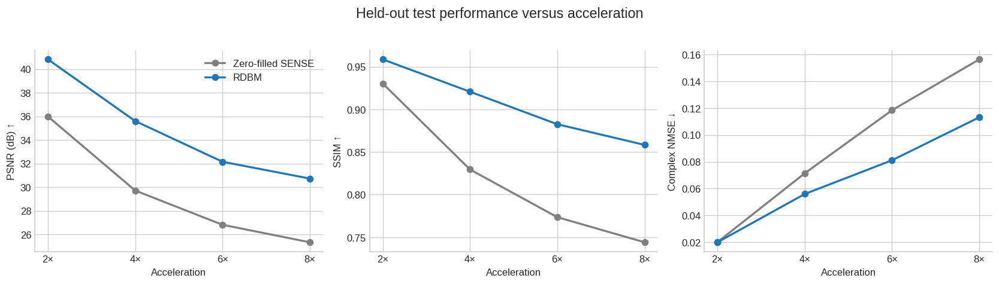

In [31]:
rates = np.array(sorted(multirate))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for axis, metric, label in zip(
    axes,
    ("psnr", "ssim", "nmse"),
    ("PSNR (dB) ↑", "SSIM ↑", "Complex NMSE ↓"),
):
    axis.plot(
        rates,
        [multirate[rate]["zero_filled"][metric] for rate in rates],
        marker="o",
        linewidth=2,
        color="gray",
        label="Zero-filled SENSE",
    )
    axis.plot(
        rates,
        [multirate[rate]["rdbm"][metric] for rate in rates],
        marker="o",
        linewidth=2,
        color="tab:blue",
        label="RDBM",
    )
    axis.set_xticks(rates, [f"{rate}×" for rate in rates])
    axis.set_xlabel("Acceleration")
    axis.set_ylabel(label)
axes[0].legend(frameon=False)
fig.suptitle("Held-out test performance versus acceleration", y=1.03, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_acceleration_comparison.png", bbox_inches="tight")
plt.show()


### Matched reconstruction output

The same held-out slice is reconstructed by every final model using the same
diffusion seed. Image and error-map display scales are shared across rates, so
the increasing difficulty is visually comparable.

**Sample:** `file_brain_AXT1POST_207_2070244:10` — same representative slice as the 4x notebook.

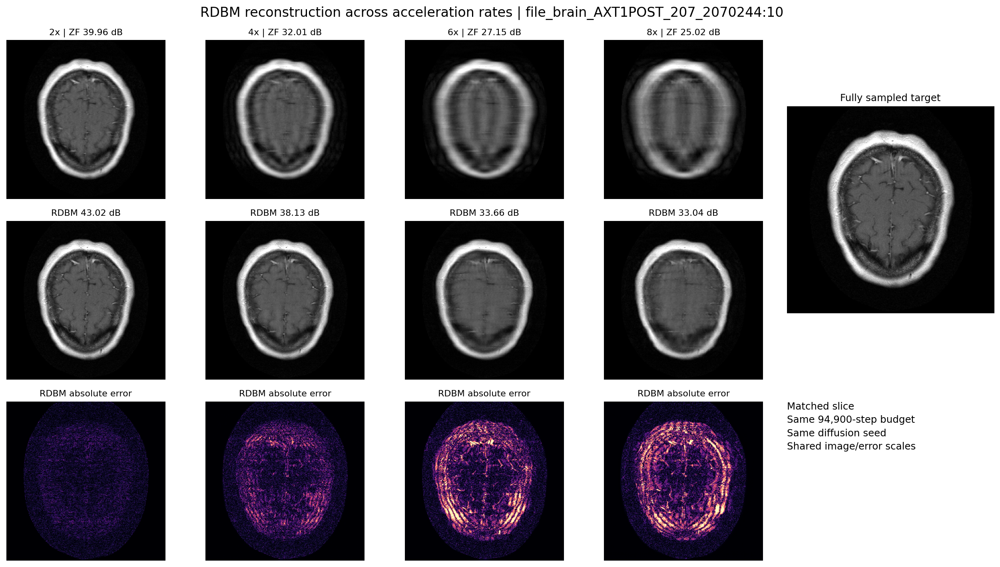

In [24]:
acceleration_figure = FIGURE_DIR / "acceleration_comparison" / "rdbm_acceleration_comparison.png"
acceleration_metadata_path = FIGURE_DIR / "acceleration_comparison" / "rdbm_acceleration_comparison.json"
acceleration_metadata = read_json(acceleration_metadata_path)
display(Markdown(
    f"**Sample:** `{acceleration_metadata['sample_id']}` — "
    f"{acceleration_metadata['selection_reason']}."
))
display(Image(filename=str(acceleration_figure)))

## Inference-time data-consistency ablation

This ablation uses the selected trained checkpoint and disables consistency during
all reverse-diffusion stages and final correction. It measures dependence on the
physics layer at inference; it is not a separately trained no-consistency model.

Method,PSNR,SSIM,Complex NMSE,Measurement residual
Zero-filled,29.716,0.8295,0.07136,0.16224
RDBM without DC,25.725,0.8446,0.14652,0.35220
RDBM with DC,35.601,0.9207,0.05591,0.14497


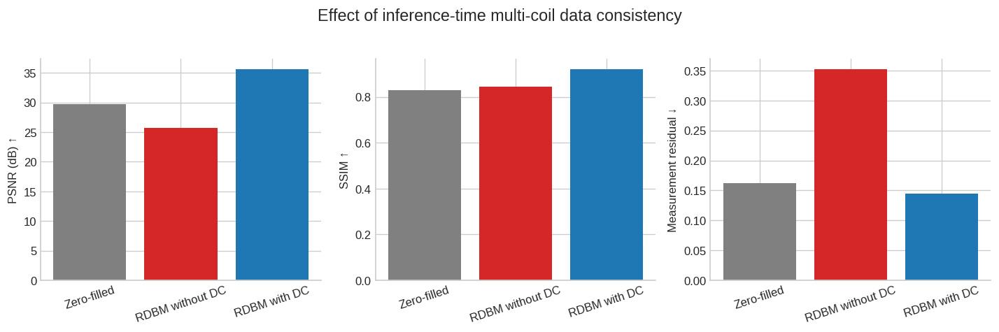

In [25]:
dc_effect = ""
if no_dc is None:
    display(Markdown("No data-consistency ablation summary was found."))
else:
    methods = [
        ("Zero-filled", test["zero_filled"]),
        ("RDBM without DC", no_dc["rdbm"]),
        ("RDBM with DC", test["rdbm"]),
    ]
    display(html_table(
        ["Method", "PSNR", "SSIM", "Complex NMSE", "Measurement residual"],
        [[name, f"{m['psnr']:.3f}", f"{m['ssim']:.4f}", f"{m['nmse']:.5f}",
          f"{m['measurement_residual']:.5f}"] for name, m in methods],
    ))
    dc_effect = (
        f"- Disabling inference-time data consistency reduces PSNR by "
        f"**{test['rdbm']['psnr'] - no_dc['rdbm']['psnr']:.2f} dB** and raises "
        f"measurement residual from **{test['rdbm']['measurement_residual']:.3f}** to "
        f"**{no_dc['rdbm']['measurement_residual']:.3f}**.\n"
    )

    labels = [name for name, _ in methods]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for axis, metric, label in zip(
        axes,
        ("psnr", "ssim", "measurement_residual"),
        ("PSNR (dB) ↑", "SSIM ↑", "Measurement residual ↓"),
    ):
        axis.bar(labels, [values[metric] for _, values in methods], color=["gray", "tab:red", "tab:blue"])
        axis.set_ylabel(label)
        axis.tick_params(axis="x", rotation=18)
    fig.suptitle("Effect of inference-time multi-coil data consistency", y=1.03, fontsize=14)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "data_consistency_ablation_metrics.png", bbox_inches="tight")
    plt.show()

## Performance by acquisition

Subgroup counts are small, especially for AXFLAIR and AXT1PRE (two test volumes
each), so these values are diagnostic rather than definitive.

Acquisition,Volumes,Slices,PSNR,SSIM,Complex NMSE
AXFLAIR,2,32,28.51 → 32.37,0.7856 → 0.8586,0.1538 → 0.2748
AXT1POST,10,158,29.99 → 36.06,0.8333 → 0.9296,0.0560 → 0.0201
AXT1PRE,2,28,29.56 → 36.55,0.8545 → 0.9378,0.0655 → 0.0163


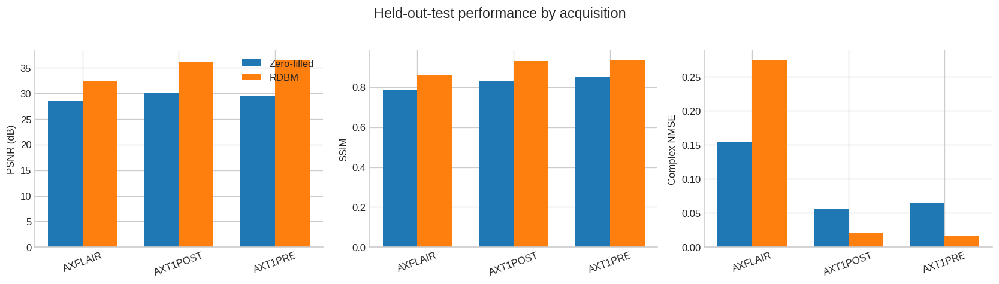

In [26]:
acquisition_rows = []
for acquisition, group in test["by_acquisition"].items():
    zf, rdbm = group["zero_filled"], group["rdbm"]
    acquisition_rows.append([
        acquisition,
        group["volume_count"],
        group["slice_count"],
        f"{zf['psnr']:.2f} → {rdbm['psnr']:.2f}",
        f"{zf['ssim']:.4f} → {rdbm['ssim']:.4f}",
        f"{zf['nmse']:.4f} → {rdbm['nmse']:.4f}",
    ])
display(html_table(
    ["Acquisition", "Volumes", "Slices", "PSNR", "SSIM", "Complex NMSE"],
    acquisition_rows,
))

acquisitions = list(test["by_acquisition"])
x = np.arange(len(acquisitions))
width = 0.36
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for axis, metric, label in zip(axes, ("psnr", "ssim", "nmse"), ("PSNR (dB)", "SSIM", "Complex NMSE")):
    zf_values = [test["by_acquisition"][name]["zero_filled"][metric] for name in acquisitions]
    rdbm_values = [test["by_acquisition"][name]["rdbm"][metric] for name in acquisitions]
    axis.bar(x - width / 2, zf_values, width, label="Zero-filled")
    axis.bar(x + width / 2, rdbm_values, width, label="RDBM")
    axis.set_xticks(x, acquisitions, rotation=20)
    axis.set_ylabel(label)
axes[0].legend(frameon=False)
fig.suptitle("Held-out-test performance by acquisition", y=1.03, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_by_acquisition.png", bbox_inches="tight")
plt.show()

## Per-volume generalization

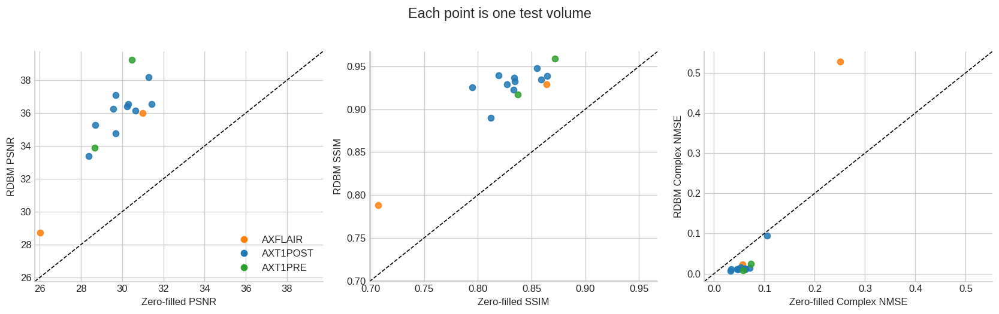

In [27]:
colors = {"AXFLAIR": "tab:orange", "AXT1POST": "tab:blue", "AXT1PRE": "tab:green"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for axis, metric, label in zip(axes, ("psnr", "ssim", "nmse"), ("PSNR", "SSIM", "Complex NMSE")):
    for volume in test["volumes"]:
        axis.scatter(
            volume["zero_filled"][metric],
            volume["rdbm"][metric],
            color=colors[volume["acquisition"]],
            alpha=0.85,
        )
    limits = np.array(axis.get_xlim() + axis.get_ylim())
    low, high = limits.min(), limits.max()
    axis.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
    axis.set_xlim(low, high)
    axis.set_ylim(low, high)
    axis.set_xlabel(f"Zero-filled {label}")
    axis.set_ylabel(f"RDBM {label}")
handles = [
    plt.Line2D([0], [0], marker="o", linestyle="", color=color, label=name)
    for name, color in colors.items()
]
axes[0].legend(handles=handles, frameon=False)
fig.suptitle("Each point is one test volume", y=1.03, fontsize=14)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_per_volume.png", bbox_inches="tight")
plt.show()

## Per-slice PSNR gains

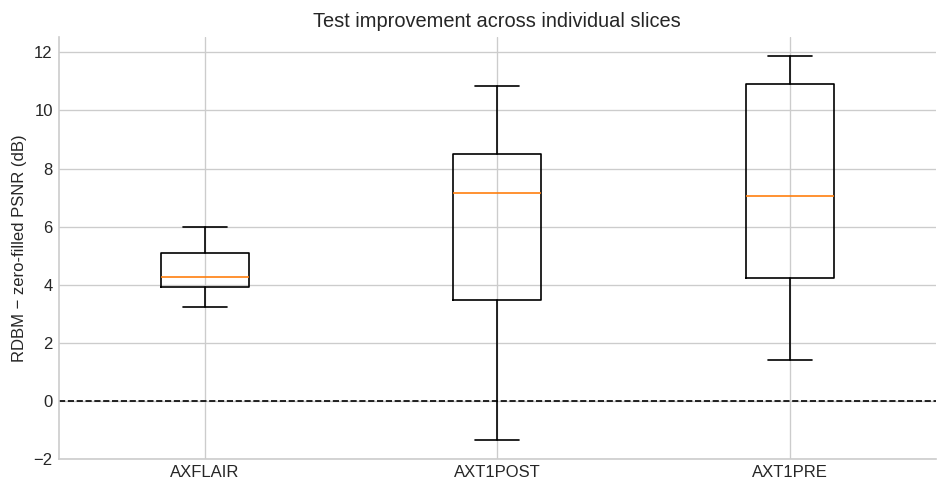

In [28]:
slice_metrics_path = test_path.parent / "slice_metrics.jsonl"
slice_rows = [json.loads(line) for line in slice_metrics_path.read_text().splitlines() if line.strip()]
groups = {
    acquisition: [
        row["rdbm_psnr"] - row["zero_filled_psnr"]
        for row in slice_rows
        if row["acquisition"] == acquisition
    ]
    for acquisition in acquisitions
}

fig, axis = plt.subplots(figsize=(8, 4.2))
axis.boxplot([groups[name] for name in acquisitions], tick_labels=acquisitions, showfliers=False)
axis.axhline(0, color="black", linestyle="--", linewidth=1)
axis.set_ylabel("RDBM − zero-filled PSNR (dB)")
axis.set_title("Test improvement across individual slices")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "test_slice_psnr_gain.png", bbox_inches="tight")
plt.show()

## Reconstruction progression example

The example is selected as the test slice closest to the median PSNR gain, rather
than choosing the visually best case. The first panel compares training checkpoints;
the second shows the final model's reverse-diffusion trajectory. All magnitude images
and error maps use consistent display scales within each figure.

**Representative sample:** `file_brain_AXT1POST_207_2070244:10` (median test-slice PSNR gain).

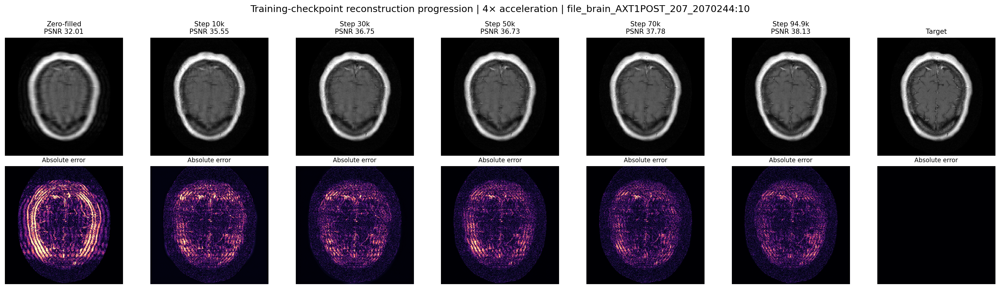

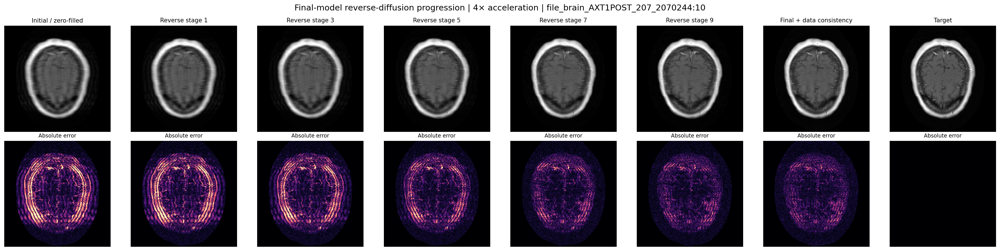

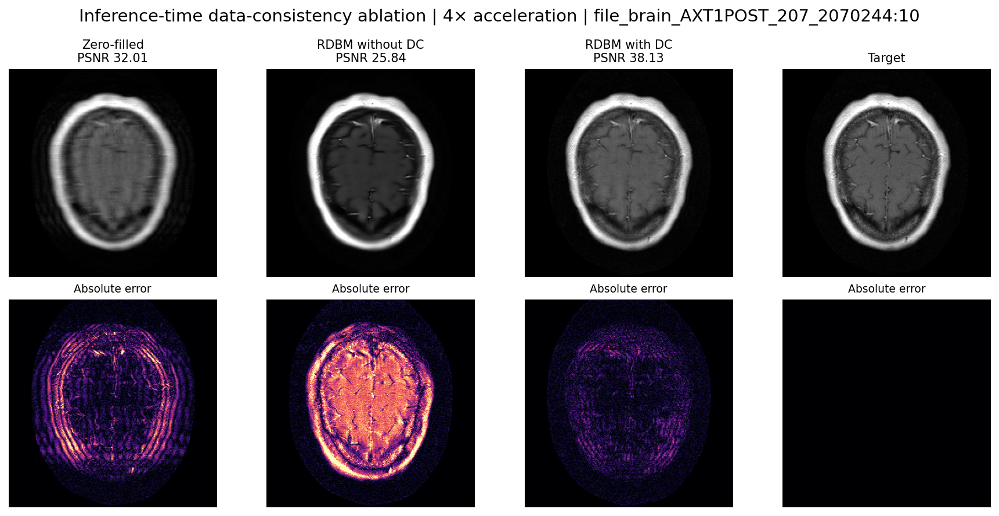

In [29]:
qualitative_dir = FIGURE_DIR / "qualitative"
checkpoint_progression = qualitative_dir / "checkpoint_progression.png"
reverse_progression = qualitative_dir / "reverse_diffusion_progression.png"
dc_ablation_image = qualitative_dir / "data_consistency_ablation.png"
progression_metadata_path = qualitative_dir / "progression_metadata.json"

if checkpoint_progression.exists() and reverse_progression.exists():
    progression_metadata = read_json(progression_metadata_path)
    display(Markdown(
        f"**Representative sample:** `{progression_metadata['sample_id']}` "
        f"({progression_metadata['selection_reason']})."
    ))
    display(Image(filename=str(checkpoint_progression), width=3000))
    display(Image(filename=str(reverse_progression), width=3000))
    if dc_ablation_image.exists():
        display(Image(filename=str(dc_ablation_image), width=2400))
else:
    display(Markdown(
        "Progression figures have not been generated yet. Run "
        "`./scripts/add_rdbm_progression_to_notebook.sh` on the GPU workstation."
    ))